In [7]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.legend_handler import HandlerBase

In [ ]:
plt.rcParams.update({
    'text.usetex': True,
    'font.family': 'serif',
})

# Change this to any saved result under output/
# npz_path = 'output/result_Mc5_R5_sddr_generic_logB2_50steps_32499951.npz' # HM waveform
npz_path = 'output/result_Mc50_R50_sddr_generic_logB2_50steps_32811803.npz'
data = np.load(npz_path)

n_Mc = len(np.unique(data['Mc']))
n_R = len(np.unique(data['R_orbit']))
Mc_array = np.unique(data['Mc'])
R_orbit_array = np.unique(data['R_orbit'])
snr_grid_1 = data['snr_1'].reshape((n_Mc, n_R))
snr_grid_2 = data['snr_2'].reshape((n_Mc, n_R))
y_Eins_1 = float(data['y_Eins_1']) # y=0.5
y_Eins_2 = float(data['y_Eins_2']) # y=1
print(f'Loaded {npz_path}: n_Mc={n_Mc}, n_R={n_R}, y=({y_Eins_1:g}, {y_Eins_2:g})')

Loaded output/result_Mc50_R50_sddr_generic_logB2_50steps_32811803.npz: n_Mc=50, n_R=50, y=(0.5, 1)


/tmp/ipykernel_1722382/2049683894.py:2: RuntimeWarning: invalid value encountered in log10
  log10_snr = np.log10(snr_grid_1)
/tmp/ipykernel_1722382/2049683894.py:54: RuntimeWarning: invalid value encountered in log10
  log10_snr_c = np.log10(snr_grid)
/tmp/ipykernel_1722382/2049683894.py:56: UserWarning: The following kwargs were not used by contour: 'linewidth'
  cont = ax.contour(


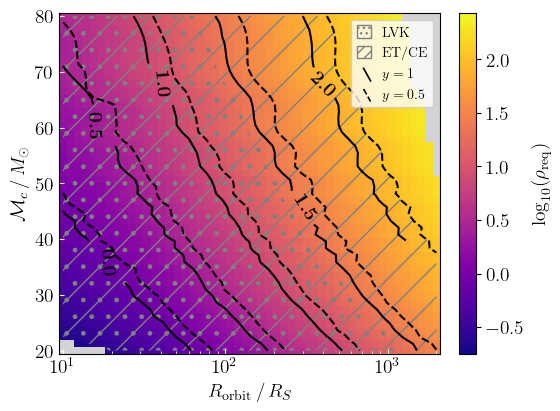

In [41]:
fig, ax = plt.subplots(1, 1, figsize=(5.5, 4), constrained_layout=True)
log10_snr = np.log10(snr_grid_1)
log10_snr = np.where(log10_snr < -3, np.nan, log10_snr)
ax.set_facecolor('lightgrey')
cmap = plt.cm.plasma.copy()
cmap.set_bad(color='lightgrey')
_min, _max = np.nanmin(log10_snr), np.nanmax(log10_snr)
midpoint = (_max + _min) / 2
half_range = (_max - _min) / 2 * 1.05
norm = colors.TwoSlopeNorm(vmin=midpoint - half_range, vcenter=midpoint, vmax=midpoint + half_range)

im = ax.pcolormesh(R_orbit_array, Mc_array, log10_snr, cmap=cmap, norm=norm, shading='nearest')

# Hatch regions reachable at given detector SNR
_shade_floor = float(np.nanmin(log10_snr)) - 1.0
for _level, _hatch, _edge in [
        (np.log10(100.0), '/', '0.5'),   # ET/CE
        (np.log10(20.0), '.', '0.5'),      # LVK
]:
    _cs = ax.contourf(
        R_orbit_array, Mc_array, log10_snr,
        levels=[_shade_floor, _level], colors='none', hatches=[_hatch],
    )
    for _coll in getattr(_cs, 'collections', [_cs]):
        _coll.set_edgecolor(_edge)
        _coll.set_linewidth(0.0)

legend_handles = [
    Patch(facecolor='none', edgecolor='0.5', hatch='...', label=r'LVK'),
    Patch(facecolor='none', edgecolor='0.5', hatch='///', label=r'ET/CE'),
]
class HandlerBackslash(HandlerBase):
    """Draw a backslash in the legend instead of a horizontal line."""

    def create_artists(self, legend, orig_handle,
                       xdescent, ydescent, width, height, fontsize, trans):
        line = Line2D(
            [5,10], [7, -2],
            color=orig_handle.get_color(),
            linewidth=orig_handle.get_linewidth(),
            linestyle=orig_handle.get_linestyle(),
            transform=trans,
        )
        return [line]


y_legend_handles = []
for snr_grid, color, linestyle, y_val, contour_label in zip(
        [snr_grid_2, snr_grid_1],
        ['black', 'black'],
        ['solid', 'dashed'],
        [y_Eins_2, y_Eins_1],
        [rf'$y = {y_Eins_2:g}$', rf'$y = {y_Eins_1:g}$']):
    log10_snr_c = np.log10(snr_grid)
    cont_snrs = [0.0, 0.5, 1.0, 1.5, 2.0, 2.5]
    cont = ax.contour(
        R_orbit_array, Mc_array, log10_snr_c,
        colors=[color], levels=cont_snrs, linestyles=linestyle, linewidth=1,
    )
    if linestyle == 'solid':
        labels = {lvl: rf'\textbf{{{snr}}}' for lvl, snr in zip(cont.levels, cont_snrs)}
        ax.clabel(cont, fmt=labels, fontsize=14)
    y_handle = Line2D([0], [0], color=color, linewidth=1.2, linestyle=linestyle, label=contour_label)
    legend_handles.append(y_handle)
    y_legend_handles.append(y_handle)
ax.legend(
    handles=legend_handles,
    handlelength=1,
    handleheight=1,
    loc='upper right',
    fontsize=10,
    handler_map={h: HandlerBackslash() for h in y_legend_handles},
)
ax.tick_params(which='both', direction='in', labelsize=14, colors='white', labelcolor='black')

ax.set_xscale('log')
ax.set_xlabel(r'$R_{\rm orbit}\,/\,R_S$', fontsize=14)
ax.set_ylabel(r'$\mathcal{M}_c\,/\,M_\odot$', fontsize=14)
cbar = fig.colorbar(im, ax=ax, label=r'$\log_{10}(\rho_{\rm req})$')
cbar.ax.tick_params(labelsize=14)
cbar.ax.yaxis.label.set_size(14)
fig.savefig('money_plot_final.pdf')
plt.show()